[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mravanba/comp551-notebooks/blob/master/MLP.ipynb)

# Multilayer Perceptron (MLP)
Our goal here is to implement a two-layer neural network for binary classification, train it using gradient descent and use it to classify the Iris dataset.
Our model is
$$
\hat{y} = \sigma \left ( W \sigma \left ( V x \right ) \right)
$$
where we have $M$ hidden units and $D$ input features -- that is $w \in \mathbb{R}^{M}$, and $V \in \mathbb{R}^{M \times D}$. For simplicity here we do not include a bias parameter for each layer. Key to our implementation is the gradient calculation. We follow the notation used in the slides here.

In [1]:
import numpy as np
#%matplotlib notebook
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.core.debugger import set_trace
import warnings
warnings.filterwarnings('ignore')

In [2]:
logistic = lambda z: 1./ (1 + np.exp(-z))

class MLP:

    def __init__(self, M = 64):
        self.M = M

    def fit(self, x, y, optimizer):
        N,D = x.shape
        def gradient(x, y, params):
            v, w = params
            z = logistic(np.dot(x, v)) #N x M
            yh = logistic(np.dot(z, w))#N
            dy = yh - y #N
            dw = np.dot(z.T, dy)/N #M
            dz = np.outer(dy, w) #N x M
            dv = np.dot(x.T, dz * z * (1 - z))/N #D x M
            dparams = [dv, dw]
            return dparams

        w = np.random.randn(self.M) * .01
        v = np.random.randn(D,self.M) * .01
        params0 = [v,w]
        self.params = optimizer.run(gradient, x, y, params0)
        return self

    def predict(self, x):
        v, w = self.params
        z = logistic(np.dot(x, v)) #N x M
        yh = logistic(np.dot(z, w))#N
        return yh

In [8]:
# נחשב את אחוז הדיוק של המודל על הנתונים שלנו
predictions = model.predict(x) > 0.5
accuracy = np.mean(predictions == y) * 100
print(f"אחוז הדיוק של המודל: {accuracy:.2f}%")

אחוז הדיוק של המודל: 94.67%


דמיין שיש לנו מחשב שרוצה ללמוד להבדיל בין שני סוגים של פרחי איריס (איריס סגול ואיריס צהוב) לפי הגודל שלהם. הקוד מורכב משלושה חלקים עיקריים:

1. המוח המלאכותי (הרשת הניורונים - MLP)
זהו מודל שמחקה את אופן הפעולה של המוח שלנו. הוא מורכב משלבים:

קלט: מקבל את המידע על הפרח (אורך ורוחּ עלי הגביע).
שכבה נסתרת: כמו "מחשבים קטנים" בתוך המוח שמעבדין את הנתונים ומחפשים חוקיות.
פלגב: נותן ניחוש סופי - האם הפרח הוא מסוג "צהוב" או לא.
פונקציית הלוגיסטית (logistic): הופכת כל מספר שמתקבל לערך שבין 0 ל-1 (כמו אחוזי ביחון: "אני בטוח ב-90% שזה צהוב").

In the implementation above we have used a list data structure to maintain model parameters and their gradients. Below I have modified the `GradientDescent` class to also work with a list of parameters. One sournce of confusion in the above implementation is the gradient calculation. While in the slides during the lectures
we calculated the partial derivative for individual parameters, here, we use vector and matrix operations to calculate the derivative for *all* parameters.

In [3]:
class GradientDescent:

    def __init__(self, learning_rate=.001, max_iters=1e4, epsilon=1e-8):
        self.learning_rate = learning_rate
        self.max_iters = max_iters
        self.epsilon = epsilon

    def run(self, gradient_fn, x, y, params):
        norms = np.array([np.inf])
        t = 1
        while np.any(norms > self.epsilon) and t < self.max_iters:
            grad = gradient_fn(x, y, params)
            for p in range(len(params)):
                params[p] -= self.learning_rate * grad[p]
            t += 1
            norms = np.array([np.linalg.norm(g) for g in grad])
        return params

2. המאמן הקשוח (GradientDescent)
בהתחלה, המוח המלאכותי עושה ניחושים אקראיים לגמרי. כאן נכעס המאמן ומתקן אותו:

המחשב מנחש ניחוש.
המאמן בוגדק את העבודה שלו ומחשב את הטעות (הגרגיאנג).
בכל סבב (איטרציה), המאמן מושך בחוטים של המוח (המשקלות - params) ומסבב אותם קצת כדי שהטעות תהיה קטנה יותר. הוא עושה את זה 20,000 פעמים עד שהמוח נהיה מומחה!


## Iris dataset
Let's apply this to do binary classification with Iris flowers dataset.
Below we run gradient descent for a large number of iterations and plot the decision boundary.

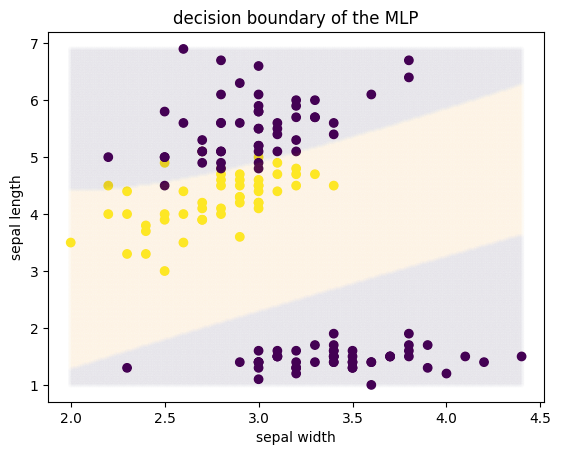

In [4]:
from sklearn import datasets
dataset = datasets.load_iris()
x, y = dataset['data'][:,[1,2]], dataset['target']
y =  y == 1
model = MLP(M=32)
optimizer = GradientDescent(learning_rate=.1, max_iters=20000)
yh = model.fit(x, y, optimizer).predict(x)
x0v = np.linspace(np.min(x[:,0]), np.max(x[:,0]), 200)
x1v = np.linspace(np.min(x[:,1]), np.max(x[:,1]), 200)
x0,x1 = np.meshgrid(x0v, x1v)
x_all = np.vstack((x0.ravel(),x1.ravel())).T
yh_all = model.predict(x_all) > .5
plt.scatter(x[:,0], x[:,1], c=y, marker='o', alpha=1)
plt.scatter(x_all[:,0], x_all[:,1], c=yh_all, marker='.', alpha=.01)
plt.ylabel('sepal length')
plt.xlabel('sepal width')
plt.title('decision boundary of the MLP')
plt.show()

להלן תרגום מקצועי ומדויק לעברית:

---

### 1. טעינת הנתונים

* `load_iris()` – מערך נתונים קלאסי (Iris dataset): 150 דגימות של פרחי אירוס, מ-3 זנים שונים (setosa, versicolor, virginica), כאשר לכל פרח נמדדו 4 מאפיינים.
* `x = data[:, [1, 2]]` – בחירה ב-2 מאפיינים בלבד מתוך הארבעה: עמודה 1 (sepal width – רוחב עלי הגביע) ועמודה 2 (petal length – אורך עלי הכותרת). הבחירה נעשתה במכוון כדי שניתן יהיה להציג את הנתונים על גבי גרף דו-ממדי פשוט.
* `y = y == 1` – המרת הבעיה לסיווג בינארי (כן/לא): הערך הופך ל-`True` עבור הזן versicolor (תווית 1), ול-`False` עבור שני הזנים האחרים. מהלך זה תואם בדיוק את מבנה ה-MLP שהוגדר, שבו שכבת הפלט כוללת נוירון בודד המחשב הסתברות.

---

### 2. יצירת המודל והאופטימייזר (Optimizer)

* `M=32` – הגדרת 32 נוירונים בשכבה הנסתרת (Hidden Layer).
* `GradientDescent` – האופטימייזר החיצוני (המממש את הממשק `optimizer.run(gradient, x, y, params0)` שנותח קודם לכן). כאן הוא מוגדר עם קצב למידה (Learning rate / step) של 0.1, ועד 20,000 איטרציות.

---

### 3. אימון וחיזוי (Training & Prediction)

* `fit(...)` מאמן את המודל ומחזיר את מופע המחלקה עצמו (`self`), מה שמאפשר לשרשר מיד קריאה ל-`.predict(x)`.
* `yh` – ערכי ההסתברות שמחשב המודל עבור נקודות מערך האימון.

---

### 4. בניית רשת קואורדינטות לקביעת גבול ההחלטה (Decision Boundary)

* `np.linspace(min, max, 200)` – פריסה של 200 נקודות במרווחים שווים לאורך כל ציר, המכסות את כל טווח הערכים של הנתונים.
* `np.meshgrid` – יצירת רשת קואורדינטות דו-ממדית בגודל $200 \times 200$.
* `np.vstack(...).ravel()` – שיטוח ("פריסה") של הרשת למבנה של 40,000 נקודות קלט נפרדות $(x_0, x_1)$, כאשר כל אחת מהן מהווה נקודה לבדיקת חיזוי המודל.

---

### 5. חיזוי על פני כל רשת הקואורדינטות

* המודל מחשב תחזית הסתברותית לכל אחת מ-40,000 הנקודות ברשת.
* `> .5` – סף ההכרעה לסיווג בינארי: נקודות שבהן ההסתברות המחושבת גדולה מ-0.5 מסווגות כשייכות לזן versicolor.

---

### 6. ויזואליזציה (גרף)

* תרשים הפיזור הראשון (`scatter`): מציג את נקודות הנתונים האמיתיות במרחב, כשהצבע נקבע לפי התווית האמיתית $y$ (עיגולים מלאים ואטומים).
* תרשים הפיזור השני: מציג את כל 40,000 הנקודות של הרשת, צבועות לפי התחזית `yh_all`, עם שקיפות גבוהה (`alpha=.01`). מכיוון שהרשת צפופה מאוד, הנקודות יוצרות יחד משטחי צבע רציפים הממחישים את **גבול ההחלטה (Decision Boundary)** – עקומה לא-לינארית המפרידה בין שני הסיווגים.
* הוספת כותרת ותוויות לצירים.

---

### מה רואים בפועל על גבי הגרף?

* **גבול החלטה לא-לינארי (עקום):** זו בדיוק הסיבה שבגללה נדרשת שכבה נסתרת ברשת. רגרסיה לוגיסטית פשוטה בעלת שכבה אחת בלבד הייתה מסוגלת למתוח אך ורק קו ישר שמפריד בין הקבוצות. לעומת זאת, MLP בעל 32 נוירונים ופונקציית שפעול סיגמואידית מסוגל "לעקם" את הגבול ולהתאים אותו לצורת הנתונים.
* **אזור הזן versicolor:** כל האזור במרחב שבו המודל חוזה ערך חיובי (`True`) נצבע בצבע ייעודי אחד, בעוד שאר המרחב נצבע בצבע השני.

---

### הערה טכנית לגבי שמות הצירים בקוד

בקוד המקורי קיימת אי-התאמה קלה: המאפיינים שנשלפו בפועל הם `[:, [1, 2]]` (כלומר רוחב עלי הגביע ואורך עלי הכותרת), אך בתוויות הצירים נכתב `'sepal width'` ו-`'sepal length'`. בפועל, הצירים מציגים את:

* **ציר ראשון:** רוחב עלי גביע (`sepal width`, עמודה 1).
* **ציר שני:** אורך עלי כותרת (`petal length`, עמודה 2).

לדיוק מרבי בהצגת הנתונים, מומלץ לעדכן את כתוביות הצירים ל-`'sepal width'` ו-`'petal length'`.

In [10]:
from sklearn.neural_network import MLPClassifier

# ניצור מודל רשמי של Scikit-Learn עם אותם פרמטרים (שכבה נסתרת של 32 נוירונים)
standard_model = MLPClassifier(hidden_layer_sizes=(32,),
                               activation='logistic',
                               solver='sgd',
                               learning_rate_init=0.1,
                               max_iter=20000,
                               random_state=42)

# אימון המודל הסטנדרטי
standard_model.fit(x, y)

# חישוב אחוזי הדיוק של המודל הסטנדרטי
standard_accuracy = standard_model.score(x, y) * 100

print(f"אחוז הדיוק של המודל הביתה-שלנו (MLP): {accuracy:.2f}%")
print(f"אחוז הדיוק של המודל הסטנדרטי (scikit-learn): {standard_accuracy:.2f}%")

אחוז הדיוק של המודל הביתה-שלנו (MLP): 94.67%
אחוז הדיוק של המודל הסטנדרטי (scikit-learn): 94.67%
